In [1]:
import os
import cv2
import numpy as np
import torch
import torchvision.models as models
import torchvision.transforms as transforms
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
from tqdm.notebook import tqdm
from IPython.display import display, Image as IPyImage

In [2]:
DATASET_DIR = r"C:\Users\ksenia\Desktop\uni\image_recognition_uni\02_lab\dataset"
OUTPUT_DIR = r"C:\Users\ksenia\Desktop\uni\image_recognition_uni\02_lab\results"
os.makedirs(OUTPUT_DIR, exist_ok=True)

GROUND_TRUTH = {
    "0.jpg": True, "2.jpg": True, "3.jpeg": True, "4.jpg": True, "5.jpg": True,
    "6.jpg": True, "7.jpg": True, "8.jpg": True, "9.jpg": True, "10.jpg": True
}

# Параметры алгоритма
CONFIDENCE_THRESHOLD = 0.25  # Порог уверенности для класса "кот"
MAX_PROPOSALS = 1500         # Максимум гипотез на изображение (эвристика)

# Получаем список файлов
image_files = sorted(
    [f for f in os.listdir(DATASET_DIR) if f.lower().endswith((".jpg", ".jpeg", ".png"))],
    key=lambda x: int(os.path.splitext(x)[0]) if os.path.splitext(x)[0].isdigit() else 0
)
print(f"Найдено изображений: {len(image_files)}")

Найдено изображений: 10


In [3]:
print("Загрузка модели ResNet18...")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)
model.eval()
model.to(device)

# Индексы классов кошек в ImageNet
CAT_INDICES = {
    281: "tabby cat", 282: "tiger cat", 283: "Persian cat", 
    284: "Egyptian cat", 285: "lynx"
}

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

Загрузка модели ResNet18...


In [4]:
def classify_region(region_img):
    """
    Принимает numpy array (BGR или RGB), возвращает (is_cat, max_prob, label)
    """
    # Конвертируем в RGB для PIL, если пришло в BGR из OpenCV
    if len(region_img.shape) == 3 and region_img.shape[2] == 3:
        # Проверка, не BGR ли это (OpenCV по умолчанию читает в BGR)
        # Но для надежности просто конвертируем
        pil_img = Image.fromarray(cv2.cvtColor(region_img, cv2.COLOR_BGR2RGB)).convert("RGB")
    else:
        pil_img = Image.fromarray(region_img).convert("RGB")
        
    tensor = transform(pil_img).unsqueeze(0).to(device)

    with torch.no_grad():
        output = model(tensor)
        probs = torch.nn.functional.softmax(output, dim=1)[0]

    # Берём максимальную вероятность среди классов кошек
    cat_probs = {idx: probs[idx].item() for idx in CAT_INDICES}
    best_idx = max(cat_probs, key=cat_probs.get)
    best_prob = cat_probs[best_idx]

    is_cat = best_prob >= CONFIDENCE_THRESHOLD
    return is_cat, best_prob, CAT_INDICES[best_idx]

In [5]:
# Счётчики метрик
TP, FP, FN, TN = 0, 0, 0, 0
results_data = []

print("Начинаем обработку изображений...")

for img_name in tqdm(image_files, desc="Обработка"):
    img_path = os.path.join(DATASET_DIR, img_name)
    img = cv2.imread(img_path)
    if img is None:
        continue

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    h_img, w_img = img.shape[:2]
    img_area = h_img * w_img

    # 1. Selective Search
    ss = cv2.ximgproc.segmentation.createSelectiveSearchSegmentation()
    ss.setBaseImage(img)
    ss.switchToSelectiveSearchFast()
    rects = ss.process()
    total_hypotheses = len(rects)

    # 2. Эвристическое отсечение (Negative)
    filtered_rects = []
    rejected_by_heuristic = 0
    for (x, y, w, h) in rects:
        area = w * h
        if area < 0.01 * img_area or area > 0.80 * img_area:
            rejected_by_heuristic += 1
            continue
        filtered_rects.append((x, y, w, h))

    if len(filtered_rects) > MAX_PROPOSALS:
        rejected_by_heuristic += len(filtered_rects) - MAX_PROPOSALS
        filtered_rects = filtered_rects[:MAX_PROPOSALS]

    positive_hypotheses = len(filtered_rects)
    negative_hypotheses = rejected_by_heuristic

    # 3. Классификация гипотез — собираем ВСЕ регионы с котом
    cat_found = False
    cat_regions = []   # список: [(x1, y1, x2, y2, prob), ...]

    for (x, y, w, h) in filtered_rects:
        x1, y1 = max(0, x), max(0, y)
        x2, y2 = min(w_img, x + w), min(h_img, y + h)
        region = img[y1:y2, x1:x2]

        if region.size == 0:
            continue

        is_cat, prob, label = classify_region(region)

        if is_cat:
            cat_found = True
            cat_regions.append((x1, y1, x2, y2, prob))

    # Сортируем по убыванию вероятности — первые самые «уверенные»
    cat_regions.sort(key=lambda r: r[4], reverse=True)

    cat_regions_count = len(cat_regions)
    not_cat_count = positive_hypotheses - cat_regions_count

    # 4. Обновление метрик
    actual_positive = GROUND_TRUTH.get(img_name, False)
    if actual_positive and cat_found:
        TP += 1; verdict = "TP"
    elif not actual_positive and cat_found:
        FP += 1; verdict = "FP"
    elif actual_positive and not cat_found:
        FN += 1; verdict = "FN"
    else:
        TN += 1; verdict = "TN"

    results_data.append({
        "Файл": img_name,
        "Всего гипотез": total_hypotheses,
        "Positive (классиф.)": positive_hypotheses,
        "Negative (эвристика)": negative_hypotheses,
        "Найдено 'кот'": cat_regions_count,
        "Ground Truth": "Кот" if actual_positive else "Нет кота",
        "Предсказание": "Кот" if cat_found else "Нет кота",
        "Вердикт": verdict,
        "All_Cat_Regions": cat_regions,   # <-- теперь список всех регионов
    })

print("✅ Обработка завершена!")

Начинаем обработку изображений...


Обработка:   0%|          | 0/10 [00:00<?, ?it/s]

✅ Обработка завершена!


In [6]:
df = pd.DataFrame(results_data)

# В таблице скрываем колонку со списком боксов (иначе она раздует вывод)
display(df.drop(columns=["All_Cat_Regions"]).style.set_properties(**{'text-align': 'center'}))

# Расчет метрик
P = TP + FN
N = FP + TN
PP = TP + FP
PN = FN + TN

accuracy = (TP + TN) / (P + N) if (P + N) > 0 else 0.0
precision = TP / PP if PP > 0 else 0.0
recall = TP / P if P > 0 else 0.0

print("\n" + "="*50)
print("📊 ИТОГОВЫЕ МЕТРИКИ")
print("="*50)
print(f"Accuracy  = (TP + TN) / Total = ({TP} + {TN}) / {P+N} = {accuracy:.4f}")
print(f"Precision = TP / (TP + FP)    = {TP} / {PP} = {precision:.4f}")
print(f"Recall    = TP / (TP + FN)    = {TP} / {P} = {recall:.4f}")
print("="*50)
print(f"Матрица ошибок:\n TP={TP}, FP={FP}\n FN={FN}, TN={TN}")

,Файл,Всего гипотез,Positive (классиф.),Negative (эвристика),Найдено 'кот',Ground Truth,Предсказание,Вердикт
0,0.jpg,9553,1500,8053,0,Кот,Нет кота,FN
1,2.jpg,9310,1500,7810,30,Кот,Кот,TP
2,3.jpeg,7361,1500,5861,5,Кот,Кот,TP
3,4.jpg,2363,1048,1315,154,Кот,Кот,TP
4,5.jpg,3977,1276,2701,171,Кот,Кот,TP
5,6.jpg,4247,1181,3066,86,Кот,Кот,TP
6,7.jpg,11573,1500,10073,0,Кот,Нет кота,FN
7,8.jpg,5858,1500,4358,0,Кот,Нет кота,FN
8,9.jpg,4524,1150,3374,8,Кот,Кот,TP
9,10.jpg,5583,1500,4083,7,Кот,Кот,TP



📊 ИТОГОВЫЕ МЕТРИКИ
Accuracy  = (TP + TN) / Total = (7 + 0) / 10 = 0.7000
Precision = TP / (TP + FP)    = 7 / 7 = 1.0000
Recall    = TP / (TP + FN)    = 7 / 10 = 0.7000
Матрица ошибок:
 TP=7, FP=0
 FN=3, TN=0


🖼️ Визуализация ВСЕХ регионов с котом (показываем 10 картинок):


C:\Users\ksenia\AppData\Local\Temp\ipykernel_7724\1195749060.py:26: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('hsv', max(len(regions), 1))


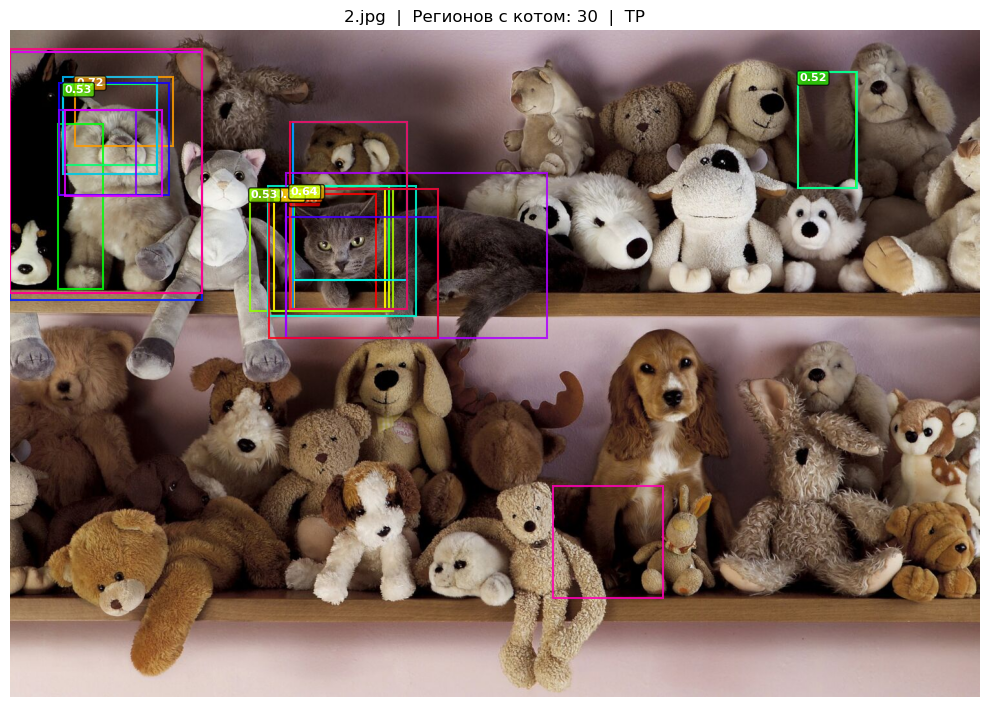

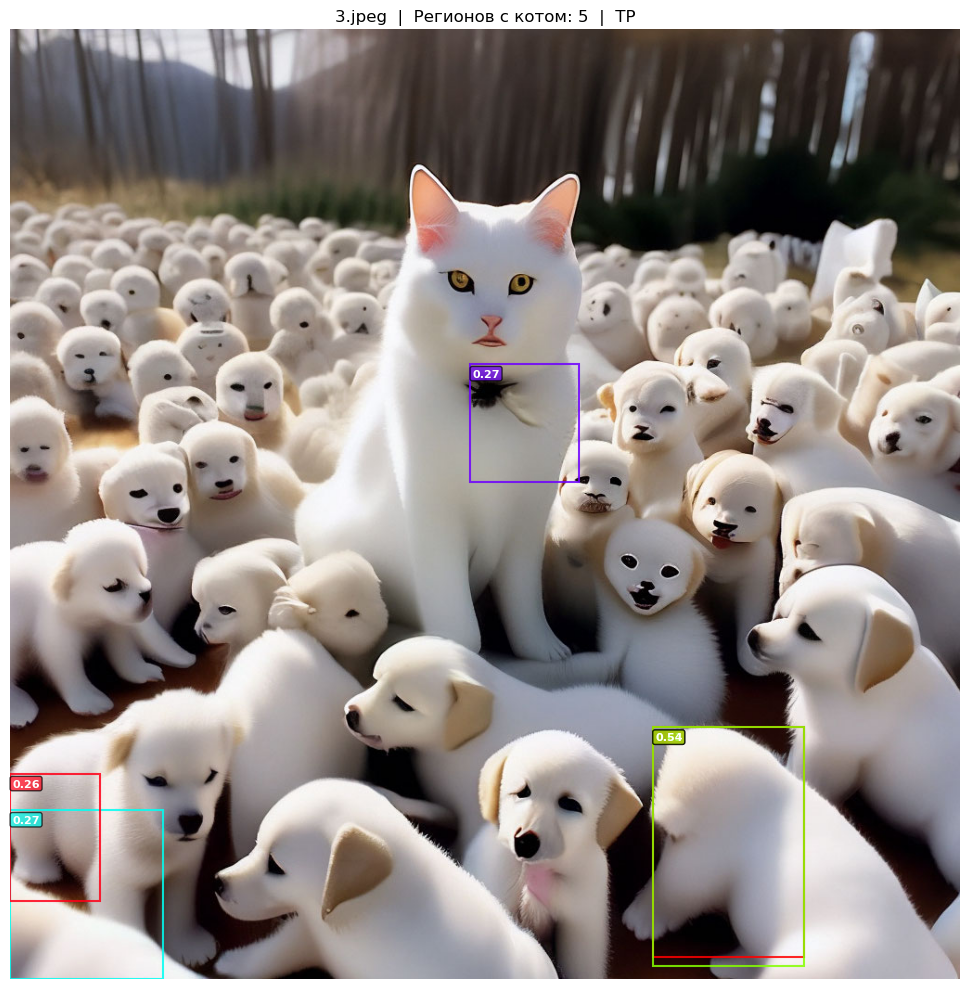

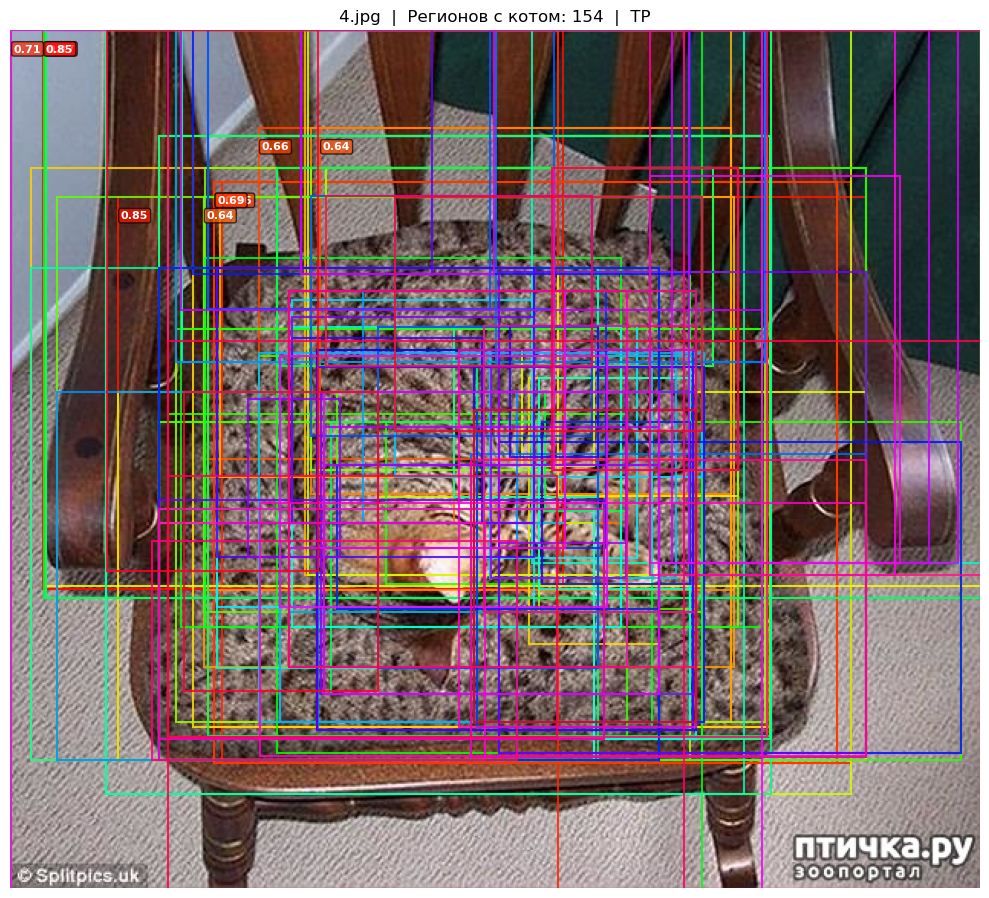

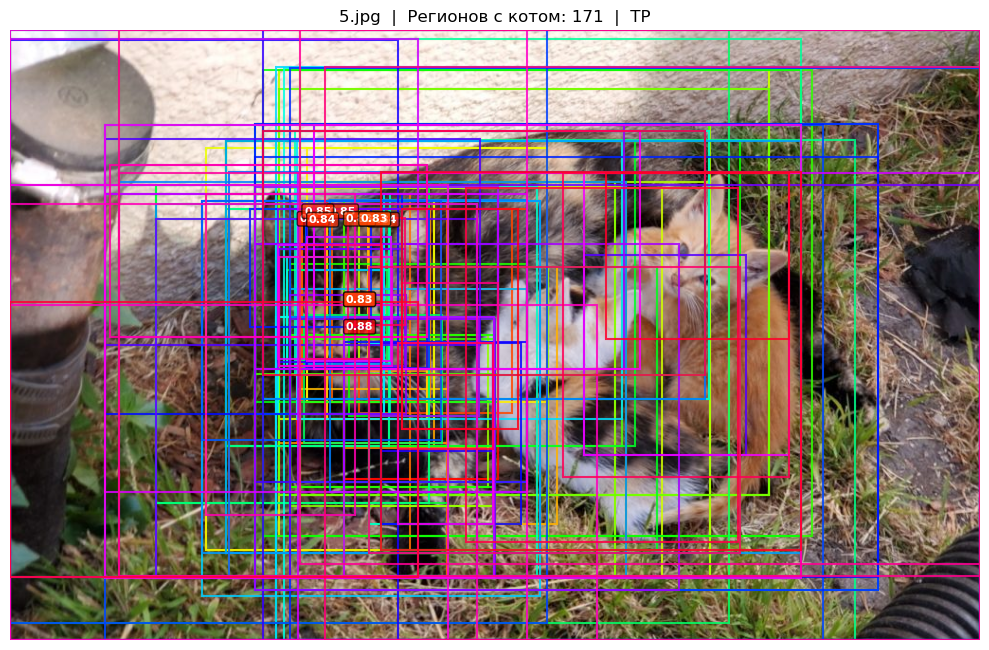

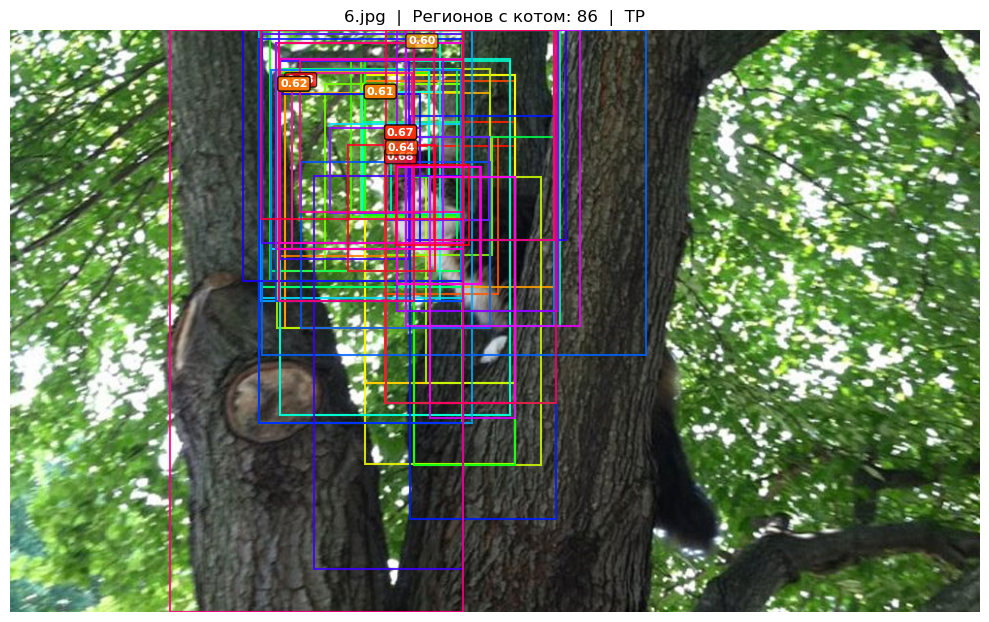

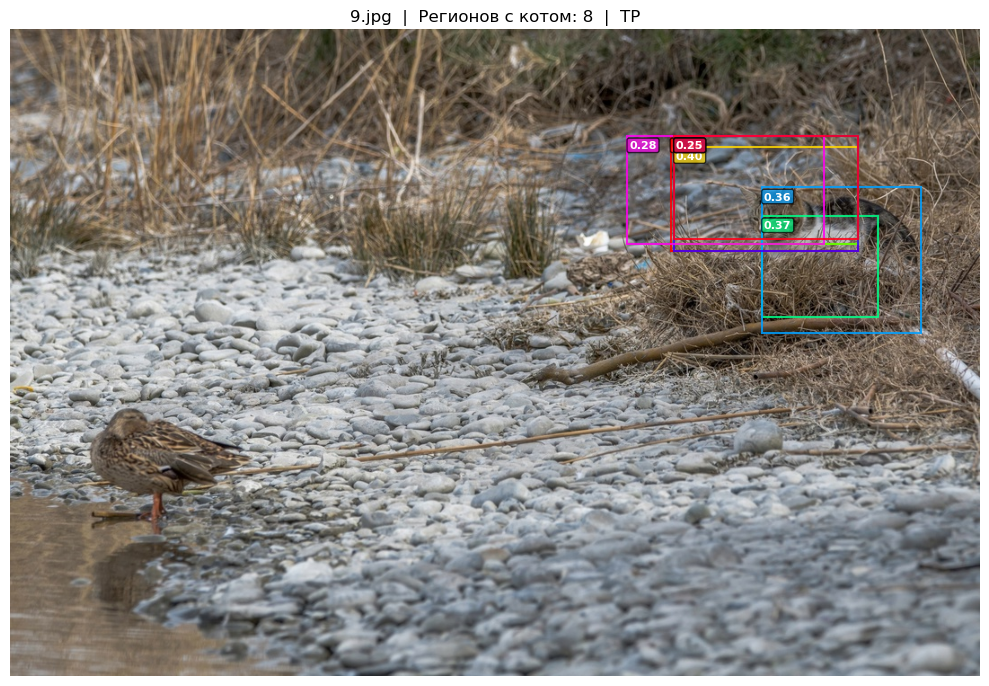

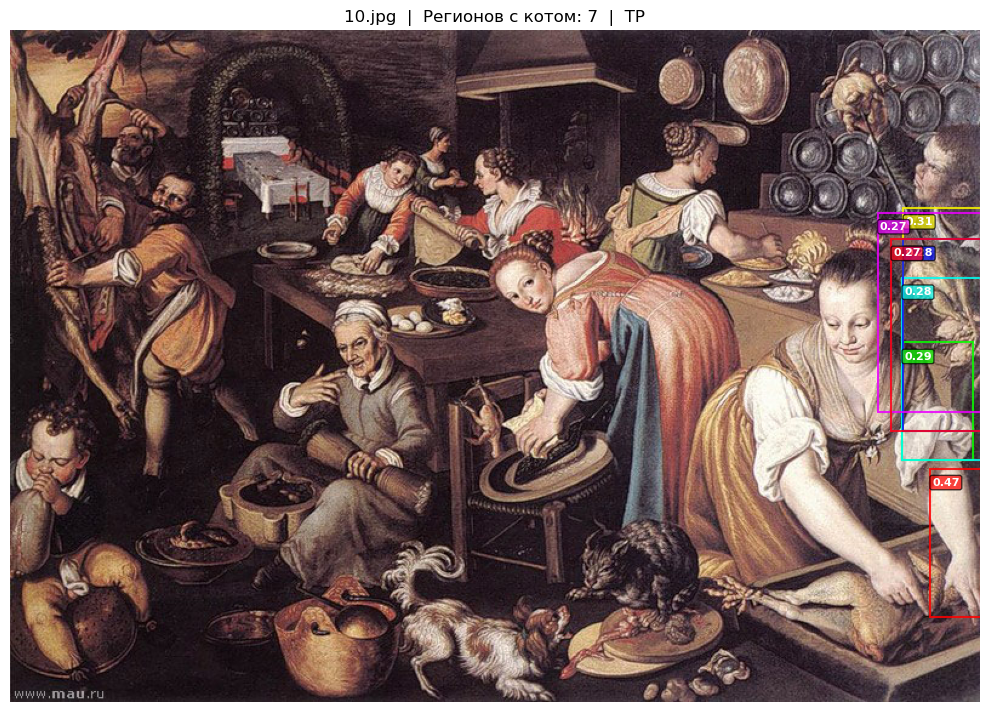

In [7]:
# Сколько картинок показывать (поставьте len(df), чтобы показать все)
NUM_TO_SHOW = 10

# Сколько подписей вероятности рисовать (чтобы не захламлять картинку)
NUM_LABELS = 10

print(f"🖼️ Визуализация ВСЕХ регионов с котом (показываем {NUM_TO_SHOW} картинок):")

shown = 0
for _, row in df.iterrows():
    regions = row["All_Cat_Regions"]
    if len(regions) == 0:
        continue
    if shown >= NUM_TO_SHOW:
        break

    img_name = row["Файл"]
    img_path = os.path.join(DATASET_DIR, img_name)
    img = cv2.imread(img_path)
    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    fig, ax = plt.subplots(figsize=(10, 10))
    ax.imshow(img_rgb)

    # Палитра цветов для рамок (циклическая, если регионов много)
    cmap = plt.cm.get_cmap('hsv', max(len(regions), 1))

    for i, (x1, y1, x2, y2, prob) in enumerate(regions):
        color = cmap(i / max(len(regions), 1))
        rect = patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor=color, facecolor='none', alpha=0.85
        )
        ax.add_patch(rect)

        # Подписываем вероятность только у самых «уверенных» регионов
        if i < NUM_LABELS:
            ax.text(x1 + 2, y1 + 14, f"{prob:.2f}",
                    color='white', fontsize=8, weight='bold',
                    bbox=dict(boxstyle='round,pad=0.2', fc=color, alpha=0.7))

    n_cat = row["Найдено 'кот'"]
    ax.set_title(f"{img_name}  |  Регионов с котом: {n_cat}  |  {row['Вердикт']}")
    ax.axis('off')
    plt.tight_layout()
    plt.show()

    shown += 1

if shown == 0:
    print("Не найдено ни одного региона с котом. Попробуйте снизить CONFIDENCE_THRESHOLD в Ячейке 2.")